# 02. EDA hành vi mua và chốt định nghĩa churn

Mục tiêu: chốt ba tham số của bài toán churn bằng dữ liệu, không chọn cảm tính:
- `W`: độ dài cửa sổ nhãn (churn = không mua trong `W` tháng sau mốc cắt)
- `L`: tập khách xét (có ít nhất một đơn hợp lệ trong `L` năm trước mốc cắt)
- Lịch mốc cắt cho train, validation, test

Kèm theo: phân tích cohort, tác động của khuyến mãi, phân phối lợi nhuận gộp tương lai (cơ sở cho hồi quy CLV).

Dữ liệu đã làm sạch theo `clean.py` (notebook 01). "Đơn" ở đây luôn là đơn hợp lệ.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "../src")
from to_parquet import load_tables
from clean import clean_tables
from viz import C, INK, INK2, save

t = clean_tables(load_tables())
o, oi, c, promos = t["orders"], t["order_items"], t["customers"], t["promotions"]
v = o[o.is_valid].sort_values(["customer_id", "order_date"]).reset_index(drop=True)
v["prev_date"] = v.groupby("customer_id").order_date.shift()
v["next_date"] = v.groupby("customer_id").order_date.shift(-1)
order_gp = oi.groupby("order_id").gross_profit.sum()
v["gp"] = v.order_id.map(order_gp)
DATA_END = v.order_date.max()
print("Đơn hợp lệ:", len(v), "| khách:", v.customer_id.nunique(), "| dữ liệu tới:", DATA_END.date())


def snapshot(cutoff, w_months=12, l_years=None):
    # Mỗi dòng một khách có đơn trước cutoff: recency (năm), churn trong W tháng, lợi nhuận gộp trong W tháng
    cutoff = pd.Timestamp(cutoff)
    end = cutoff + pd.DateOffset(months=w_months)
    past = v[v.order_date < cutoff]
    fut = v[(v.order_date >= cutoff) & (v.order_date < end)]
    s = past.groupby("customer_id").agg(last=("order_date", "max"), n=("order_id", "size"))
    s["recency_y"] = (cutoff - s["last"]).dt.days / 365.25
    if l_years is not None:
        s = s[s.recency_y <= l_years]
    s["churn"] = (~s.index.isin(fut.customer_id)).astype(int)
    s["future_gp"] = fut.groupby("customer_id").gp.sum().reindex(s.index, fill_value=0)
    return s

Đơn hợp lệ: 580208 | khách: 87839 | dữ liệu tới: 2022-12-31


## 1. Khoảng cách giữa hai lần mua và chọn `W`

Đo trên các đơn có đủ 3 năm theo dõi phía sau, để lần mua lại xa vẫn được nhìn thấy (tránh bị cắt cụt bởi ngày cuối dữ liệu). So sánh hai giai đoạn: trước cú gãy 2018 (đơn đặt 2013–2017) và sau cú gãy (đơn đặt năm 2019).

In [2]:
periods = {"đơn đặt 2013–2017": ("2013-01-01", "2017-12-31"), "đơn đặt 2019": ("2019-01-01", "2019-12-31")}
rows, gaps = [], {}
for name, (a, b) in periods.items():
    s = v[(v.order_date >= a) & (v.order_date <= b)]
    d = (s.next_date - s.order_date).dt.days
    gaps[name] = d
    rep3 = (d <= 1095).sum()
    for w in (6, 12, 18, 24, 36):
        days = round(w * 30.44)
        rows.append((name, w, (d <= days).mean(), (d <= days).sum() / rep3))
cover = pd.DataFrame(rows, columns=["giai đoạn", "W (tháng)", "P(mua lại trong W)", "% lượt mua lại (≤3 năm) rơi vào W"])
cover.pivot(index="W (tháng)", columns="giai đoạn", values="% lượt mua lại (≤3 năm) rơi vào W").round(3)

giai đoạn,đơn đặt 2013–2017,đơn đặt 2019
W (tháng),,
6,0.589,0.437
12,0.794,0.655
18,0.890,0.787
24,0.944,0.881
36,1.000,1.000


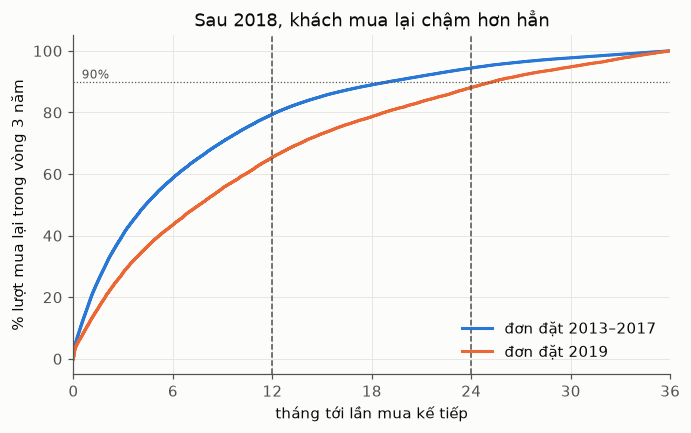

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for i, (name, d) in enumerate(gaps.items()):
    x = np.sort(d.dropna().clip(upper=1100).values)
    x = x[x <= 1095]
    ax.plot(x / 30.44, np.arange(1, len(x) + 1) / len(x) * 100, color=C[i], label=name)
for w in (12, 24):
    ax.axvline(w, color=INK2, lw=1, ls="--")
ax.axhline(90, color=INK2, lw=0.8, ls=":")
ax.annotate("90%", (0.5, 91), color=INK2, fontsize=8)
ax.set(xlabel="tháng tới lần mua kế tiếp", ylabel="% lượt mua lại trong vòng 3 năm",
       title="Sau 2018, khách mua lại chậm hơn hẳn", xlim=(0, 36), xticks=range(0, 37, 6))
ax.legend(frameon=False, loc="lower right")
save(fig, "02_repurchase_gap_ecdf")

**Tiêu chí ban đầu "`W` chứa 90% lượt mua lại" cho ra `W` ≈ 24–30 tháng** ở giai đoạn sau 2018 (12 tháng chỉ chứa ~65%). Nhưng `W` = 24 tháng không dùng được với dữ liệu này:

| `W` | Mốc test muộn nhất | Mốc validation | Mốc train muộn nhất (nhãn phải xong trước validation) | Hệ quả |
| :--- | :--- | :--- | :--- | :--- |
| 12 tháng | 2022-01 | 2021-01 | 2020-01 | Train, validation, test đều nằm sau cú gãy 2018 |
| 24 tháng | 2021-01 | 2019-01 | 2017-01 | **Toàn bộ train nằm trước cú gãy**: model học một thế giới mà tỷ lệ giữ chân ~57%, rồi bị chấm ở thế giới ~41% |

**Chốt `W` = 12 tháng**, vì:
1. **Dữ liệu:** chỉ `W` = 12 cho phép train, validation, test cùng nằm trong chế độ sau 2018 (notebook 01, mục 5).
2. **Mùa vụ:** 12 tháng chứa trọn một chu kỳ mùa (đỉnh tháng 4–6), nhãn không phụ thuộc mốc cắt rơi vào tháng nào.
3. **Kinh doanh:** chiến dịch giữ chân và CLV đều lập theo năm; CLV 12 tháng khớp đúng cửa sổ nhãn.

**Cái giá phải trả** (đo ngay bên dưới): một phần khách bị gán "churn" thật ra chỉ mua thưa và quay lại sau 12 tháng. Nhãn vì vậy nên hiểu là **"không mua trong 12 tháng tới"**, không phải "rời bỏ vĩnh viễn".

In [4]:
s = snapshot("2020-01-01", l_years=3)
later = v[(v.order_date >= "2021-01-01")].customer_id.unique()
back = pd.Series(s.index.isin(later), index=s.index).groupby(s.churn).mean()
print(f"Mốc 2020-01: khách bị gán churn quay lại mua trong 2021–2022: {back[1]:.1%}")
print(f"             khách không churn tiếp tục mua trong 2021–2022:     {back[0]:.1%}")

Mốc 2020-01: khách bị gán churn quay lại mua trong 2021–2022: 38.7%
             khách không churn tiếp tục mua trong 2021–2022:     67.0%


39% khách "churn" quay lại trong 2 năm sau đó, so với 67% ở nhóm không churn. Hai nhóm vẫn khác nhau rõ rệt, nên nhãn có ý nghĩa, nhưng đây là **nguồn lỗi nền** của mọi model churn trên dữ liệu này: một phần "báo nhầm" (false positive) thật ra là khách mua thưa. Ghi vào phần phân tích lỗi (Task 7).

## 2. Chọn tập khách xét `L`

Khách đã lâu không mua có còn là "khách đang hoạt động" để dự báo churn không? Xem xác suất mua trong 12 tháng tới theo số năm kể từ lần mua cuối.

recency_y,0–1,1–2,2–3,3–4,4–5,>5
số khách theo recency,,,,,,
2019-01,35636,16913,10425,7279,5701,5767
2020-01,25336,20864,12405,8556,6194,10266
2021-01,22501,15163,15081,10091,7355,14962
2022-01,22075,13403,10364,11829,8547,20303


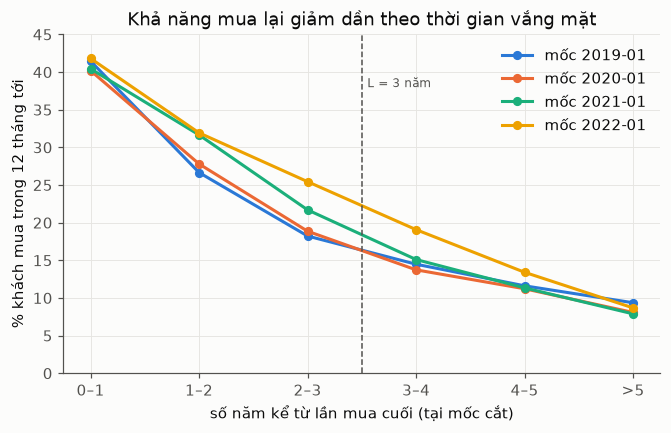

In [5]:
bins = [0, 1, 2, 3, 4, 5, 20]
labels = ["0–1", "1–2", "2–3", "3–4", "4–5", ">5"]
fig, ax = plt.subplots(figsize=(7, 4))
rows = []
for i, cut in enumerate(["2019-01-01", "2020-01-01", "2021-01-01", "2022-01-01"]):
    s = snapshot(cut)
    r = s.groupby(pd.cut(s.recency_y, bins, labels=labels), observed=True).churn.agg(["size", "mean"])
    ax.plot(labels, (1 - r["mean"]) * 100, color=C[i], marker="o", ms=5, label=f"mốc {cut[:7]}")
    rows.append(r["size"].rename(cut[:7]))
ax.axvline(2.5, color=INK2, lw=1, ls="--")
ax.annotate("L = 3 năm", (2.55, 38), color=INK2, fontsize=8)
ax.set(xlabel="số năm kể từ lần mua cuối (tại mốc cắt)", ylabel="% khách mua trong 12 tháng tới",
       title="Khả năng mua lại giảm dần theo thời gian vắng mặt", ylim=(0, 45))
ax.legend(frameon=False)
save(fig, "02_repurchase_by_recency")
pd.DataFrame(rows).rename_axis("số khách theo recency")

In [6]:
rows = []
for cut in ["2019-01-01", "2020-01-01", "2021-01-01", "2022-01-01"]:
    s = snapshot(cut)
    for L in (None, 3, 2):
        x = s if L is None else s[s.recency_y <= L]
        rows.append((cut[:7], "toàn bộ" if L is None else f"L = {L}", len(x), x.churn.mean(),
                     roc_auc_score(x.churn, x.recency_y)))
auc = pd.DataFrame(rows, columns=["mốc", "tập khách", "số khách", "tỷ lệ churn", "AUC của riêng recency"])
auc.pivot(index="mốc", columns="tập khách", values=["số khách", "tỷ lệ churn", "AUC của riêng recency"]).round(3)

số khách                   tỷ lệ churn                 \
tập khách    L = 2    L = 3  toàn bộ       L = 2  L = 3 toàn bộ   
mốc                                                               
2019-01    52549.0  62974.0  81721.0       0.633  0.664   0.713   
2020-01    46200.0  58605.0  83621.0       0.654  0.687   0.749   
2021-01    37664.0  52745.0  85153.0       0.631  0.674   0.757   
2022-01    35478.0  45842.0  86521.0       0.619  0.648   0.754   

          AUC của riêng recency                 
tập khách                 L = 2  L = 3 toàn bộ  
mốc                                             
2019-01                   0.607  0.635   0.682  
2020-01                   0.593  0.623   0.687  
2021-01                   0.563  0.607   0.695  
2022-01                   0.568  0.591   0.699

**Chốt `L` = 3 năm.**
- Khách vắng 3 năm trở lên chỉ còn 8–19% khả năng mua lại, và nhóm này **phình to theo thời gian** (khách cũ tích tụ: từ 19 nghìn ở mốc 2019-01 lên 41 nghìn ở mốc 2022-01). Nếu giữ họ, tỷ lệ churn bị đẩy lên 75% và AUC của riêng recency tăng giả tạo từ 0,59–0,64 lên 0,68–0,70, vì model chỉ cần nhận ra "khách đã bỏ đi từ lâu", một việc không cần ML.
- Về kinh doanh, khách vắng hơn 3 năm thuộc bài toán **tái kích hoạt (win-back)**, khác với giữ chân khách đang hoạt động.
- Không chọn `L` = 2 vì nhóm vắng 2–3 năm vẫn có 18–25% khả năng mua lại, đúng là nhóm "đang rơi rụng" mà chiến dịch giữ chân cần nhắm tới.

Với `L` = 3, tỷ lệ churn ổn định ở 65–69% từ mốc 2019 trở đi, và recency đứng riêng đạt AUC ≈ 0,59–0,64 (mốc để các model sau phải vượt). AUC của recency giảm dần qua các mốc vì nhóm khách vắng 2–3 năm ngày càng đông và khó đoán hơn.

## 3. Tỷ lệ churn theo mốc cắt và lịch train / validation / test

,L = 3,toàn bộ khách,số khách (L = 3)
mốc,,,
2016-01-01,0.506,0.518,63743
2016-07-01,0.518,0.541,64328
2017-01-01,0.523,0.555,64274
2017-07-01,0.521,0.564,64117
2018-01-01,0.542,0.591,63810
2018-07-01,0.621,0.669,63914
2019-01-01,0.664,0.713,62974
2019-07-01,0.677,0.733,60572
2020-01-01,0.687,0.749,58605


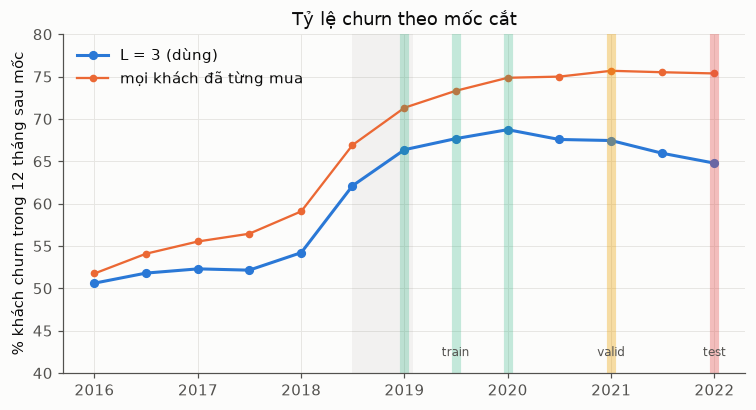

In [7]:
cuts = pd.date_range("2016-01-01", "2022-01-01", freq="6MS")
curve = pd.DataFrame([(cu, snapshot(cu, l_years=3).churn.mean(), snapshot(cu).churn.mean(), len(snapshot(cu, l_years=3)))
                      for cu in cuts], columns=["mốc", "L = 3", "toàn bộ khách", "số khách (L = 3)"]).set_index("mốc")

TRAIN = ["2019-01-01", "2019-07-01", "2020-01-01"]
VALID, TEST = "2021-01-01", "2022-01-01"
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve.index, curve["L = 3"] * 100, color=C[0], marker="o", ms=5, label="L = 3 (dùng)")
ax.plot(curve.index, curve["toàn bộ khách"] * 100, color=C[1], marker="o", ms=4, lw=1.5, label="mọi khách đã từng mua")
for d in TRAIN:
    ax.axvline(pd.Timestamp(d), color=C[2], lw=6, alpha=0.25)
ax.axvline(pd.Timestamp(VALID), color=C[3], lw=6, alpha=0.35)
ax.axvline(pd.Timestamp(TEST), color=C[7], lw=6, alpha=0.35)
for d, txt in [(TRAIN[1], "train"), (VALID, "valid"), (TEST, "test")]:
    ax.annotate(txt, (pd.Timestamp(d), 42), ha="center", color=INK2, fontsize=8)
ax.axvspan(pd.Timestamp("2018-07-01"), pd.Timestamp("2019-01-31"), color=INK2, alpha=0.06, lw=0)
ax.set(ylabel="% khách churn trong 12 tháng sau mốc", title="Tỷ lệ churn theo mốc cắt", ylim=(40, 80))
ax.legend(frameon=False, loc="upper left")
save(fig, "02_churn_rate_by_cutoff")
curve.round(3)

,mốc cắt,tập,nhãn từ,nhãn đến hết,số khách,tỷ lệ churn
0,2019-01-01,train,2019-01-01,2019-12-31,62974,0.664
1,2019-07-01,train,2019-07-01,2020-06-30,60572,0.677
2,2020-01-01,train,2020-01-01,2020-12-31,58605,0.687
3,2021-01-01,validation,2021-01-01,2021-12-31,52745,0.674
4,2022-01-01,test,2022-01-01,2022-12-31,45842,0.648


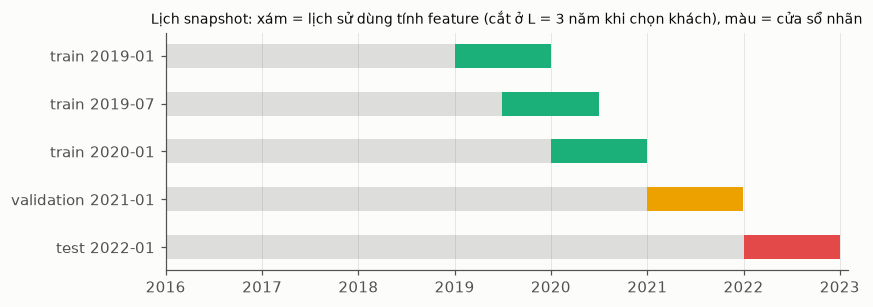

In [8]:
sched = pd.DataFrame({"mốc cắt": pd.to_datetime(TRAIN + [VALID, TEST]),
                      "tập": ["train"] * 3 + ["validation", "test"]})
sched["nhãn từ"] = sched["mốc cắt"]
sched["nhãn đến hết"] = sched["mốc cắt"] + pd.DateOffset(months=12) - pd.Timedelta(days=1)

fig, ax = plt.subplots(figsize=(8, 2.8))
color = {"train": C[2], "validation": C[3], "test": C[7]}
for i, r in sched.iterrows():
    y = len(sched) - i
    ax.barh(y, (r["mốc cắt"] - pd.Timestamp("2016-01-01")).days, left=pd.Timestamp("2016-01-01"), height=0.5,
            color=INK2, alpha=0.18)
    ax.barh(y, (r["nhãn đến hết"] - r["nhãn từ"]).days, left=r["nhãn từ"], height=0.5, color=color[r["tập"]])
ax.set_yticks(range(len(sched), 0, -1), [f'{r["tập"]} {r["mốc cắt"]:%Y-%m}' for _, r in sched.iterrows()])
ax.set(title="Lịch snapshot: xám = lịch sử dùng tính feature (cắt ở L = 3 năm khi chọn khách), màu = cửa sổ nhãn",
       xlim=(pd.Timestamp("2016-01-01"), pd.Timestamp("2023-01-31")))
ax.title.set_fontsize(9)
ax.grid(axis="y", visible=False)
save(fig, "02_snapshot_schedule")
sched["số khách"] = [len(snapshot(d, l_years=3)) for d in sched["mốc cắt"]]
sched["tỷ lệ churn"] = [snapshot(d, l_years=3).churn.mean().round(3) for d in sched["mốc cắt"]]
sched

**Chốt lịch mốc cắt:**

| Tập | Mốc cắt | Nhãn | Lý do |
| :--- | :--- | :--- | :--- |
| Train | 2019-01, 2019-07, 2020-01 | 12 tháng sau mỗi mốc | Nhãn nằm trọn trong chế độ sau cú gãy; tỷ lệ churn 66–69%, đồng đều với validation/test |
| Validation | 2021-01 | năm 2021 | Chọn model, tinh chỉnh, permutation importance |
| Test | 2022-01 | năm 2022 (dữ liệu tới 31/12/2022, đủ 12 tháng) | Chạy đúng một lần |

Hai thay đổi so với lịch dự kiến trong plan:
1. **Bỏ mốc train 2020-07.** Cửa sổ nhãn của nó (07/2020–06/2021) chồng lên năm 2021, đúng giai đoạn nhãn của validation. Giữ lại thì train đã "nhìn thấy" một nửa đáp án của validation, metric validation sẽ đẹp giả tạo. Quy tắc: nhãn của train phải kết thúc trước mốc validation, nhãn của validation phải kết thúc trước mốc test.
2. **Không dùng mốc 2018-07 trở về trước.** Cửa sổ nhãn của 2018-07 nằm ngay trên cú gãy (churn 62%, lệch hẳn so với 65–69% sau đó).

Mốc 2019-01 được giữ: feature có tính từ giai đoạn trước cú gãy, nhưng nhãn và tỷ lệ churn (66%) đã thuộc chế độ mới. Task 6 sẽ báo metric riêng cho từng mốc để kiểm tra mốc này có kéo model lệch không.

Lưu ý cho Task 4–6: cùng một khách xuất hiện ở nhiều mốc train, nên các dòng không độc lập. Không dùng k-fold ngẫu nhiên; tinh chỉnh bằng cách chia theo mốc cắt.

## 4. Cohort theo năm mua đầu tiên và theo kênh khách đến

Cohort theo **năm đơn hợp lệ đầu tiên** (không dùng `signup_date` vì cột này là nhiễu, notebook 01).

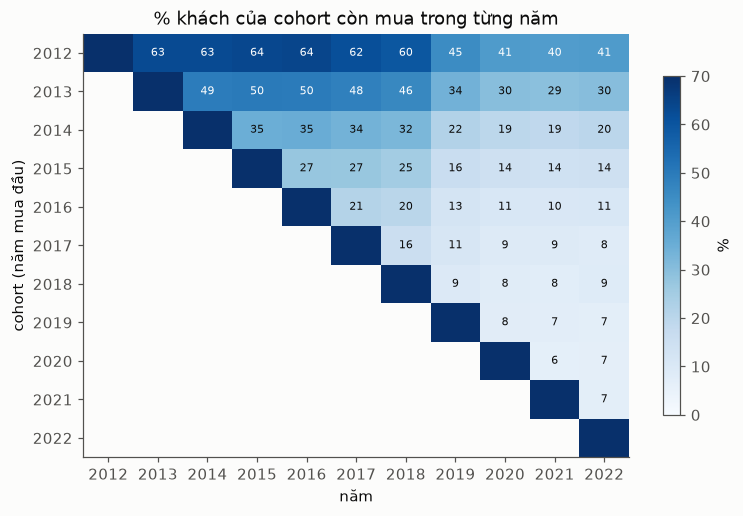

In [9]:
v["first_year"] = v.groupby("customer_id").order_date.transform("min").dt.year
v["year"] = v.order_date.dt.year
coh = v.groupby(["first_year", "year"]).customer_id.nunique().unstack()
coh_pct = coh.div(np.diag(coh.values), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 5))
masked = np.ma.masked_invalid(coh_pct.values)
im = ax.imshow(masked, cmap="Blues", vmin=0, vmax=70, aspect="auto")
for i in range(coh_pct.shape[0]):
    for j in range(coh_pct.shape[1]):
        val = coh_pct.values[i, j]
        if not np.isnan(val) and j > i:
            ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=7, color="white" if val > 40 else INK)
ax.set_xticks(range(coh_pct.shape[1]), coh_pct.columns)
ax.set_yticks(range(coh_pct.shape[0]), coh_pct.index)
ax.set(xlabel="năm", ylabel="cohort (năm mua đầu)", title="% khách của cohort còn mua trong từng năm")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="%")
save(fig, "02_cohort_retention")

**Nhận xét:**
- **Năm thứ hai quyết định:** tỷ lệ còn mua ở năm kế tiếp giảm dần theo cohort (63% với cohort 2012, chỉ 6–8% với cohort 2019 trở đi). Sau năm thứ hai, tỷ lệ gần như đi ngang: khách đã qua được năm đầu thì rất "dính".
- Cú gãy 2019 đánh vào **mọi cohort cùng lúc** (cohort 2012 từ 60% còn 45%, cohort 2015 từ 25% còn 16%), nên đó là một cú sốc toàn hệ thống, không phải do cơ cấu khách thay đổi.
- Hệ quả cho feature: **thâm niên (tenure) và số đơn quá khứ** sẽ rất quan trọng. Khách mới 1 đơn gần như chắc chắn churn; khách đã mua nhiều năm thì hiếm khi churn.

In [10]:
s = snapshot("2021-01-01", l_years=3).join(c.set_index("customer_id")[["acquisition_channel", "gender", "age_group"]])
pieces = []
for col in ["acquisition_channel", "gender", "age_group"]:
    g = s.groupby(col).agg(số_khách=("churn", "size"), tỷ_lệ_churn=("churn", "mean"), đơn_quá_khứ_TB=("n", "mean"))
    g.index = [f"{col} = {i}" for i in g.index]
    pieces.append(g)
demo = pd.concat(pieces).round(3)
print("Chênh lệch tỷ lệ churn lớn nhất trong mỗi nhóm (mốc 2021-01):")
for col in ["acquisition_channel", "gender", "age_group"]:
    r = s.groupby(col).churn.mean()
    print(f"  {col:20s} {r.min():.3f} – {r.max():.3f}")
demo

Chênh lệch tỷ lệ churn lớn nhất trong mỗi nhóm (mốc 2021-01):
  acquisition_channel  0.668 – 0.680
  gender               0.673 – 0.676
  age_group            0.671 – 0.679


,số_khách,tỷ_lệ_churn,đơn_quá_khứ_TB
acquisition_channel = direct,4233,0.680,8.449
acquisition_channel = email_campaign,6346,0.675,8.471
acquisition_channel = organic_search,15786,0.674,8.510
acquisition_channel = paid_search,10561,0.677,8.422
acquisition_channel = referral,5296,0.677,8.429
acquisition_channel = social_media,10523,0.668,8.487
gender = Female,25822,0.676,8.492
gender = Male,24898,0.673,8.453
gender = Non-binary,2025,0.673,8.404
age_group = 18-24,7324,0.679,8.391


Kênh khách đến, giới tính, nhóm tuổi không phân biệt tỷ lệ churn (chênh lệch giữa các nhóm dưới 1,5 điểm phần trăm) và số đơn trung bình. Dự đoán: nhóm nhân khẩu học sẽ đóng góp rất ít trong ablation của Task 5. Vẫn giữ chúng để ablation đo được điều đó một cách định lượng.

## 5. Khuyến mãi: có làm khách mua nhiều hơn không, và có lãi không?

In [11]:
days = pd.DataFrame({"date": pd.date_range(v.order_date.min(), DATA_END)})
days["in_promo"] = False
for _, p in promos.iterrows():
    days.loc[days.date.between(p.start_date, p.end_date), "in_promo"] = True
days["orders"] = days.date.map(v.groupby("order_date").size()).fillna(0)
days["month"] = days.date.dt.month
days = days[days.date >= "2013-01-01"]  # khuyến mãi bắt đầu từ 2013
m = days.groupby(["month", "in_promo"]).orders.mean().unstack()
m.columns = ["ngoài khuyến mãi", "trong khuyến mãi"]
m["tăng (%)"] = (m["trong khuyến mãi"] / m["ngoài khuyến mãi"] - 1) * 100
print(f"Tỷ lệ ngày có khuyến mãi: {days.in_promo.mean():.1%}")
m.round(1)

Tỷ lệ ngày có khuyến mãi: 46.7%


,ngoài khuyến mãi,trong khuyến mãi,tăng (%)
month,,,
1,80.6,138.8,72.2
2,106.4,116.1,9.1
3,114.2,225.0,97.0
4,252.4,198.8,-21.2
5,214.0,NaN,NaN
6,200.0,259.3,29.7
7,179.3,161.7,-9.8
8,160.5,181.6,13.1
9,NaN,130.8,NaN


In [12]:
items = oi.merge(v[["order_id"]], on="order_id")
items["promo"] = items.promo_id.notna()
items["margin"] = items.gross_profit / items.line_revenue
pm = items.groupby("promo").agg(số_dòng=("order_id", "size"), mức_giảm_TB=("discount_amount", "sum"),
                                 doanh_thu=("line_revenue", "sum"), lợi_nhuận_gộp=("gross_profit", "sum"),
                                 tỷ_lệ_dòng_lỗ=("gross_profit", lambda x: (x < 0).mean()))
pm["mức_giảm_TB"] = pm["mức_giảm_TB"] / (pm["doanh_thu"] + pm["mức_giảm_TB"])
pm["biên_LN_gộp"] = pm["lợi_nhuận_gộp"] / pm["doanh_thu"]
pm.index = ["không khuyến mãi", "có khuyến mãi"]
pm.round(3)

,số_dòng,mức_giảm_TB,doanh_thu,lợi_nhuận_gộp,tỷ_lệ_dòng_lỗ,biên_LN_gộp
không khuyến mãi,393282,0.000,9.852752e+09,1.921081e+09,0.002,0.195
có khuyến mãi,247720,0.138,4.199269e+09,-5.900895e+08,0.678,-0.141


,số_khách,tỷ_lệ_churn,đơn_quá_khứ_TB,tỷ_lệ_churn (khách 1 đơn)
nhóm,,,,
0%,8561,0.874,2.271,0.935
1–33%,16400,0.614,10.056,NaN
34–67%,22657,0.604,10.881,NaN
68–100%,5127,0.848,3.092,0.947


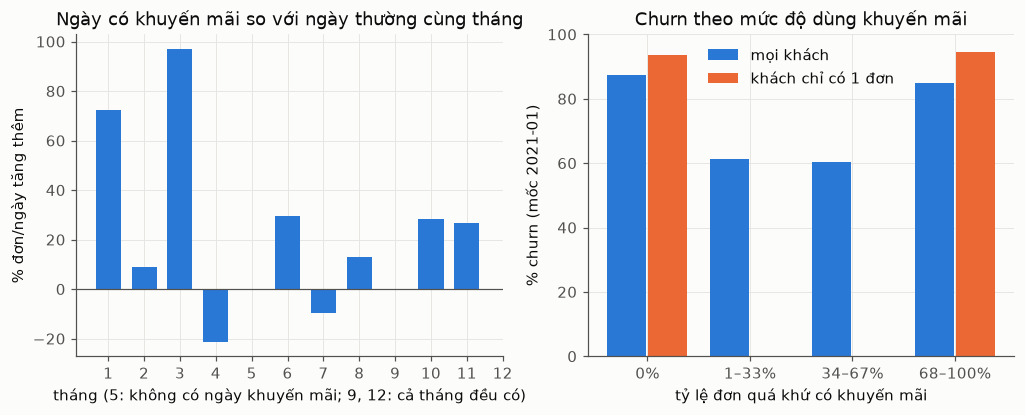

In [13]:
s = snapshot("2021-01-01", l_years=3)
promo_share = v.merge(items.groupby("order_id").promo.any().rename("promo"), on="order_id")
promo_share = promo_share[promo_share.order_date < "2021-01-01"].groupby("customer_id").promo.mean()
s["promo_share"] = promo_share
s["nhóm"] = pd.cut(s.promo_share, [-0.01, 0, 0.34, 0.67, 1], labels=["0%", "1–33%", "34–67%", "68–100%"])
pr_ch = s.groupby("nhóm", observed=True).agg(số_khách=("churn", "size"), tỷ_lệ_churn=("churn", "mean"), đơn_quá_khứ_TB=("n", "mean"))
s1 = s[s.n == 1]
pr_ch["tỷ_lệ_churn (khách 1 đơn)"] = s1.groupby("nhóm", observed=True).churn.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(m.index, m["tăng (%)"], color=C[0], width=0.7)
axes[0].axhline(0, color=INK2, lw=0.8)
axes[0].set(xlabel="tháng (5: không có ngày khuyến mãi; 9, 12: cả tháng đều có)", ylabel="% đơn/ngày tăng thêm", title="Ngày có khuyến mãi so với ngày thường cùng tháng", xticks=range(1, 13))
x = np.arange(len(pr_ch))
axes[1].bar(x - 0.2, pr_ch["tỷ_lệ_churn"] * 100, width=0.38, color=C[0], label="mọi khách")
axes[1].bar(x + 0.2, pr_ch["tỷ_lệ_churn (khách 1 đơn)"] * 100, width=0.38, color=C[1], label="khách chỉ có 1 đơn")
axes[1].set_xticks(x, pr_ch.index)
axes[1].set(xlabel="tỷ lệ đơn quá khứ có khuyến mãi", ylabel="% churn (mốc 2021-01)", title="Churn theo mức độ dùng khuyến mãi", ylim=(0, 100))
axes[1].legend(frameon=False)
save(fig, "02_promo_effect")
pr_ch.round(3)

**Nhận xét về khuyến mãi** (đọc kèm bảng và biểu đồ ở trên):
- **Khuyến mãi bán lỗ:** dòng hàng có khuyến mãi được giảm trung bình 13,8%, biên lợi nhuận gộp **−14%** và 68% dòng bị lỗ; dòng không khuyến mãi có biên +19,5%. Tổng cộng, khuyến mãi đã xóa gần 1/3 lợi nhuận gộp của phần bán thường. Đây là ràng buộc quan trọng nhất cho mô phỏng ở Task 10: **phát voucher đại trà gần như chắc chắn lỗ**, chỉ đáng phát cho khách mà `p_churn × tỷ_lệ_cứu × CLV` vượt chi phí voucher.
- **Không có bằng chứng nhất quán rằng khuyến mãi kéo thêm đơn:** so cùng tháng, ngày có khuyến mãi lúc nhiều đơn hơn (+97% tháng 3), lúc ít hơn (−21% tháng 4). Đây chỉ là tương quan: lịch khuyến mãi lặp lại cùng ngày mỗi năm, nên không tách được tác động khỏi mùa vụ. Vì vậy "tỷ lệ cứu nhờ voucher" ở Task 10 phải chạy phân tích độ nhạy, không lấy từ dữ liệu.
- **Mức dùng khuyến mãi không tự dự báo churn:** nhóm 0% và 68–100% có churn cao (85–87%) chỉ vì đó là khách ít đơn (trung bình 2–3 đơn). Xét riêng khách chỉ có 1 đơn, churn của người dùng và không dùng khuyến mãi gần như bằng nhau (93,5% so với 94,7%). Dự đoán: tỷ lệ dùng khuyến mãi sẽ yếu khi đã có số đơn trong model.

## 6. Lợi nhuận gộp 12 tháng tới: cơ sở cho hồi quy CLV

,giá trị
số khách,52745.000
= 0 (không mua),0.676
< 0 (lỗ),0.106
> 0,0.219
độ lệch (skew) của phần > 0,2.853
skew của log(1 + phần > 0),-0.590
trung vị phần > 0,3909.023
P99 phần > 0,46494.933
top 10% khách chiếm % tổng lợi nhuận dương,0.870


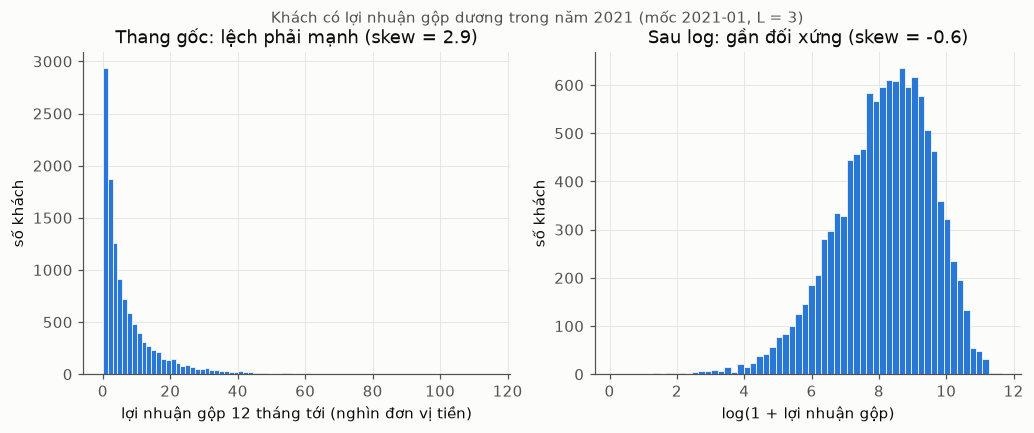

In [14]:
s = snapshot("2021-01-01", l_years=3)
g = s.future_gp
pos = g[g > 0]
stats = pd.Series({
    "số khách": len(g), "= 0 (không mua)": (g == 0).mean(), "< 0 (lỗ)": (g < 0).mean(), "> 0": (g > 0).mean(),
    "độ lệch (skew) của phần > 0": pos.skew(), "skew của log(1 + phần > 0)": np.log1p(pos).skew(),
    "trung vị phần > 0": pos.median(), "P99 phần > 0": pos.quantile(0.99),
    "top 10% khách chiếm % tổng lợi nhuận dương": pos.sort_values(ascending=False).head(len(g) // 10).sum() / pos.sum(),
})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(pos / 1e3, bins=80, color=C[0], edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set(xlabel="lợi nhuận gộp 12 tháng tới (nghìn đơn vị tiền)", ylabel="số khách", title=f"Thang gốc: lệch phải mạnh (skew = {pos.skew():.1f})")
axes[1].hist(np.log1p(pos), bins=60, color=C[0], edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(xlabel="log(1 + lợi nhuận gộp)", ylabel="số khách", title=f"Sau log: gần đối xứng (skew = {np.log1p(pos).skew():.1f})")
fig.suptitle("Khách có lợi nhuận gộp dương trong năm 2021 (mốc 2021-01, L = 3)", fontsize=10, color=INK2)
save(fig, "02_future_gp_dist")
stats.round(3).to_frame("giá trị")

**Nhận xét:**
- 67,6% khách có lợi nhuận tương lai bằng 0 (chính là khách churn). Phần dương **lệch phải rất mạnh**; sau `log(1 + x)` phân phối gần đối xứng. Đây là lý do hồi quy OLS dùng biến mục tiêu log: không log thì phần dư lệch, giả định của OLS bị vỡ, và vài khách cực lớn chi phối hệ số.
- Lợi nhuận rất tập trung: 10% khách đem lại 87% tổng lợi nhuận dương. Vì vậy hồi quy CLV được đánh giá thêm bằng khả năng xếp hạng (Spearman, tỷ lệ lợi nhuận rơi vào top 10%).
- **10,6% khách (tức 1/3 số khách có mua) đem lại lợi nhuận âm** trong năm, do mua hàng khuyến mãi lỗ hoặc được hoàn tiền (khớp với mục 5). CLV vì vậy có thể âm, và đó là thông tin có giá trị: không nên tặng voucher cho khách gây lỗ. Đề xuất cho Task 9: biến mục tiêu `sign(x) · log(1 + |x|)` để giữ thông tin "khách gây lỗ" thay vì cắt về 0, và so sánh với phương án cắt về 0.
- Số 0 chiếm đa số nên có thể cân nhắc mô hình hai phần (xác suất mua × lợi nhuận nếu mua), nối thẳng với model churn: `CLV ≈ (1 − p_churn) × E[lợi nhuận | có mua]`. Để Task 9 so sánh.

## 7. Tổng hợp quyết định

| Tham số | Giá trị | Căn cứ |
| :--- | :--- | :--- |
| `W` | 12 tháng | Chỉ `W` = 12 giữ train/validation/test cùng chế độ sau 2018; trọn một chu kỳ mùa; khớp CLV 12 tháng. Đánh đổi: 12 tháng chỉ chứa ~65% lượt mua lại, 39% khách "churn" quay lại sau đó (mục 1) |
| `L` | 3 năm | Khách vắng > 3 năm chỉ 8–19% mua lại và là bài toán win-back; giữ họ làm AUC tăng giả tạo (mục 2) |
| Train | 2019-01, 2019-07, 2020-01 | Nhãn sau cú gãy, kết thúc trước mốc validation (mục 3) |
| Validation | 2021-01 | |
| Test | 2022-01 | Đủ 12 tháng nhãn tới 31/12/2022 |
| Đơn hợp lệ | khác `cancelled`, `created` | notebook 01, R1 |
| Lợi nhuận gộp | doanh thu − tiền hoàn − giá vốn phần giữ lại | `clean.py`, R11 |

Các giá trị này được lưu trong `ml/src/config.py` để `features.py` và các notebook sau dùng chung.

In [15]:
import config
assert config.W_MONTHS == 12 and config.L_YEARS == 3
assert [d.strftime("%Y-%m-%d") for d in config.TRAIN_CUTOFFS] == TRAIN
assert config.VALID_CUTOFF == pd.Timestamp(VALID) and config.TEST_CUTOFF == pd.Timestamp(TEST)
# Không chồng lấn nhãn giữa các tập
assert max(config.TRAIN_CUTOFFS) + pd.DateOffset(months=config.W_MONTHS) <= config.VALID_CUTOFF
assert config.VALID_CUTOFF + pd.DateOffset(months=config.W_MONTHS) <= config.TEST_CUTOFF
assert config.TEST_CUTOFF + pd.DateOffset(months=config.W_MONTHS) <= config.DATA_END + pd.Timedelta(days=1)
print("config.py khớp với quyết định trong notebook.")

config.py khớp với quyết định trong notebook.
